In [1]:
import sys

sys.path.append("..")
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
import os
import json
from typing import List, Optional
from tqdm import tqdm
from classes.sample.sample_classes import SampleFRF, SingleFRFSample
from classes.signal.signal_classes import SignalFRF

In [2]:
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(["science", "ieee", "grid"])
# plt.style.use('default')

In [3]:
AXES = ["x", "y", "z"]
RADIALS = ["y", "z"]
CABLES = [1, 2, 3, 4]

In [4]:
SEQ_1_H2_PATH = Path("../data/frfs/sequence_1/h2")
SEQ_2_H2_PATH = Path("../data/frfs/sequence_2/h2")
SEQ_3_H2_PATH = Path("../data/frfs/sequence_3/h2")

SEQ_1_H1_PATH = Path("../data/frfs/sequence_1/h1")

SEQ_1_COH_PATH = Path("../data/frfs/sequence_1/coh")
SEQ_2_COH_PATH = Path("../data/frfs/sequence_2/coh")
SEQ_3_COH_PATH = Path("../data/frfs/sequence_3/coh")

In [5]:
SAMPLES_TO_AVOID = [
    datetime(2023, 2, 20, 7, 59, 0),
    datetime(2023, 3, 3, 23, 20, 0),
    datetime(2023, 3, 5, 15, 21, 0),
    datetime(2023, 3, 7, 5, 21, 0),
    datetime(2023, 5, 19, 19, 16),
    datetime(2023, 5, 29, 19, 16),
    datetime(2023, 6, 1, 11, 39),
]

In [6]:
VALID_START_DATE_S1 = datetime(2023, 1, 15)

VALID_START_DATE_S2 = datetime(2023, 4, 27, 11)
VALID_END_DATE_S2 = datetime(2023, 7, 5, 11)

VALID_START_DATE_S3 = datetime(2023, 8, 15, 15)

SEQ_1_HEALTH_END = datetime(2023, 1, 25, 10, 0, 0)
SEQ_2_HEALTH_END = datetime(2023, 5, 9, 11, 0, 0)
SEQ_3_HEALTH_END = datetime(2023, 8, 30, 11, 0, 0)

# Helper functions

In [7]:
def load_and_transform_features(
    path: Path,
    valid_start: Optional[datetime] = None,
    valid_end: Optional[datetime] = None,
    max_samples: Optional[int] = None,
    samples_to_avoid: Optional[List[datetime]] = None,
) -> List[SampleFRF]:
    files = os.listdir(path)
    frfs: List[SampleFRF] = []
    counter = 0
    for file in tqdm(files):
        with open(path / file, "r") as f:
            data = json.load(f)
        sample_frf = SampleFRF(**data)
        date = datetime.fromisoformat(sample_frf.sample_id)
        if samples_to_avoid and date in samples_to_avoid:
            continue
        if valid_start and date < valid_start:
            continue
        if valid_end and date > valid_end:
            continue
        frfs.append(sample_frf)
        counter += 1
        if max_samples and counter >= max_samples:
            break
    return frfs

In [8]:
def plot_frfs(frf: SampleFRF):
    frf_per_cable = [frf.sample_c1, frf.sample_c2, frf.sample_3, frf.sample_4]

    plt.figure(figsize=(10, 5))
    plt.plot(frf.frequencies, frf.amplitudes)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.title(f"FRF for {frf.sample_id}")
    plt.show()

In [ ]:
# import numpy as np
# from mpl_toolkits.mplot3d import Axes3D  # Needed for 3D plotting
# from typing import List, Optional


# def get_indexes(k: int, data: List[float]) -> List[int]:
#     data_arr = np.array(data)
#     data_max = np.max(data_arr)
#     data_min = np.min(data_arr)
#     delta = (data_max - data_min) / k
#     values = np.arange(data_min, data_max, delta)
#     diffs = np.abs(np.subtract.outer(data_arr, values))
#     return np.argmin(diffs, axis=0)


# def plot_3d_waterfall_one_plot_per_cable(
#     frf_list: List[SampleFRF],
#     cables: List[str] = ["1", "2", "3", "4"],
#     axes_list: List[str] = ["x", "y", "z"],
#     axes_to_combine: List[str] = ["x", "y", "z"],
#     f_min: float = 0.0,
#     f_max: float = 128.0,
#     combine_axes: bool = False,
#     db: bool = False,
#     seq: int = 0,
#     log_x: bool = False,
#     mode: str = "frf",
# ) -> None:
#     """
#     For each cable, create a 3D waterfall plot that shows the FRF magnitude
#     for each axis (x, y, z) across multiple SampleFRF objects.

#     If combine_axes is True, we compute the L2 norm of x,y,z magnitudes
#     at each frequency, plotting one line per tension value.

#     We set linestyle="-" and marker="" in ax.plot(...) to ensure
#     continuous lines with no breaks or markers.

#     Camera adjustments:
#       - ax.dist controls the apparent distance from the data (lower => closer).
#       - ax.view_init(elev, azim) sets elevation & azimuth angles.
#     """

#     axis_colors = {"x": "black", "y": "red", "z": "blue"}

#     for cable in cables:
#         fig = plt.figure(figsize=(7, 3.5), constrained_layout=True)
#         ax = fig.add_subplot(111, projection="3d")
#         ax.set_box_aspect(aspect=(1, 1, 0.25), zoom=1.0)

#         # Adjust camera angle/distance as desired
#         # ax.dist = 5
#         ax.view_init(elev=50, azim=-90)

#         # ax.set_title(f"3D Waterfall - Cable {cable}")
#         shown_labels = {}

#         for frf_obj in frf_list:
#             cable_obj = getattr(frf_obj, f"sample_c{cable}")
#             tension_value = np.round(float(cable_obj.tension), 1)

#             if combine_axes:
#                 combined_freq = None
#                 combined_mag_sqr = None

#                 for axis_name in axes_to_combine:
#                     signal_frf = getattr(cable_obj, axis_name)
#                     freq_axis = np.array(signal_frf.frequencies)
#                     mag_axis = np.array(signal_frf.abs)

#                     # Frequency cropping
#                     mask = (freq_axis >= f_min) & (freq_axis <= f_max)
#                     freq_axis = freq_axis[mask]
#                     mag_axis = mag_axis[mask]

#                     if combined_freq is None:
#                         combined_freq = freq_axis
#                         combined_mag_sqr = mag_axis**2
#                     else:
#                         if not np.allclose(combined_freq, freq_axis):
#                             raise ValueError(
#                                 "Frequency arrays differ and require alignment."
#                             )
#                         combined_mag_sqr += mag_axis**2

#                 # L2 norm
#                 combined_mag = np.sqrt(combined_mag_sqr)
#                 y_vals = np.full_like(combined_freq, tension_value)

#                 if db:
#                     combined_mag = 20 * np.log10(combined_mag)
#                 line = ax.plot(
#                     combined_freq,
#                     y_vals,
#                     combined_mag,
#                     color="k",
#                     label="L2 norm",
#                     linestyle="-",
#                     marker="",
#                     alpha=1,
#                     linewidth=0.5,
#                 )
#                 if "L2 norm" not in shown_labels:
#                     shown_labels["L2 norm"] = line[0]

#             else:
#                 # Plot separate axes
#                 for axis_name in axes_list:
#                     signal_frf = getattr(cable_obj, axis_name)
#                     freqs = np.array(signal_frf.frequencies)
#                     mag = np.array(signal_frf.abs)

#                     mask = (freqs >= f_min) & (freqs <= f_max)
#                     freqs = freqs[mask]
#                     mag = mag[mask]

#                     y_vals = np.full_like(freqs, tension_value)
#                     color = axis_colors.get(axis_name, "k")

#                     if db:
#                         mag = 20 * np.log10(mag)
#                     line = ax.plot(
#                         freqs,
#                         y_vals,
#                         mag,
#                         color=color,
#                         label=axis_name,
#                         linestyle="-",
#                         marker="",
#                         alpha=1,
#                     )
#                     if axis_name not in shown_labels:
#                         shown_labels[axis_name] = line[0]

#         ax.set_xlabel("Frequency (Hz)")
#         ax.set_ylabel("Tension (N)")
#         # ax.set_zlabel("Magnitude")
#         ax.set_xticks(np.arange(f_min, f_max + 1, 16))
#         ax.minorticks_off()
#         if log_x:
#             ax.set_xscale("log", base=2)
#         ax.set_xlim(f_min, f_max)
#         ax.set_zlim(0, 10)
#         # ax.set_zticks(np.arange(0, 11, 4))
#         ax.set_zticks([])
#         ax.xaxis.pane.set_edgecolor("black")
#         ax.yaxis.pane.set_edgecolor("black")
#         ax.zaxis.pane.set_edgecolor("black")
#         ax.xaxis.pane.fill = False
#         ax.yaxis.pane.fill = False
#         ax.zaxis.pane.fill = False
#         ax.zaxis.set_label_position("none")
#         # ax.legend(shown_labels.values(), shown_labels.keys(), loc="best", ncols=3)

#         plt.tight_layout()
#         plt.autoscale()
#         plt.savefig(
#             f"figures_frf_eda/{mode}_waterfall_cable{cable}_seq{seq}_logx{log_x}.png",
#             dpi=300,
#             bbox_inches="tight",
#         )
#         plt.show()


# def plot_2d_pcolormesh_cables_axes(
#     frf_list: List[SampleFRF],
#     cables: List[str] = ("1", "2", "3", "4"),
#     axes_list: List[str] = ("x", "y", "z"),
#     f_min: float = 0.0,
#     f_max: float = 128.0,
#     combine_axes: bool = False,
#     db: bool = False,
#     log_x: bool = False,
#     mode: str = "frf",
#     seq: int = 0,
# ) -> None:
#     """
#     Create 2D pcolormesh plots for each cable (and axis), showing tension on the Y-axis,
#     frequency on the X-axis, and color = FRF magnitude. If combine_axes=True, we
#     compute the L2 norm across x,y,z and show only one plot per cable.

#     • If combine_axes=False, we produce one plot per (cable, axis) => len(cables)*len(axes).
#     • If combine_axes=True, we produce one plot per cable (axes combined), => len(cables).

#     Frequency arrays are assumed consistent across all SampleFRF objects for a given axis
#     and cable. Tension is taken from something like:
#         tension = frf_obj.sample_c{cable}.tension

#     The 2D array for pcolormesh has:
#         - rows = different SampleFRF objects (ordered by tension)
#         - columns = frequency bins (cropped to f_min..f_max)
#         - values = magnitude (either single-axis or L2 norm)
#     """

#     for cable in cables:
#         plt.figure(figsize=(4, 3))
#         if combine_axes:
#             _plot_pcolormesh_for_cable(
#                 frf_list,
#                 cable,
#                 axes_list,
#                 f_min,
#                 f_max,
#                 plt.gca(),
#                 combine_axes=True,
#                 db=db,
#                 log_x=log_x,
#                 mode=mode,
#                 seq=seq,
#             )
#         else:
#             # We'll make one subplot per axis
#             for axis_name in axes_list:
#                 plt.figure(figsize=(10, 6))
#                 _plot_pcolormesh_for_cable(
#                     frf_list,
#                     cable,
#                     [axis_name],
#                     f_min,
#                     f_max,
#                     plt.gca(),
#                     combine_axes=False,
#                     db=db,
#                     log_x=log_x,
#                     mode=mode,
#                     seq=seq,
#                 )
#                 plt.show()

#         if combine_axes:
#             plt.show()


# def _plot_pcolormesh_for_cable(
#     frf_list: List[SampleFRF],
#     cable: str,
#     axes_list: List[str],
#     f_min: float,
#     f_max: float,
#     ax: plt.Axes,
#     combine_axes: bool,
#     db: bool = False,
#     log_x: bool = False,
#     mode: str = "frf",
#     seq: int = 0,
# ) -> None:
#     """
#     Helper: For a single cable (and possibly multiple axes if combine_axes=True), gather all
#     FRFs from frf_list, build a 2D matrix (rows = FRFs, columns = freq bins),
#     and do pcolormesh with tension on Y, freq on X, color = magnitude (or L2 magnitude).
#     """

#     # Gather tension, frequencies, and magnitudes for each FRF
#     tensions = []
#     mags_2d = []  # each entry is 1D array of magnitude across freq

#     freqs_ref = None

#     # 1) Collect data from all FRFs for this cable
#     for frf_obj in frf_list:
#         cable_obj = getattr(frf_obj, f"sample_c{cable}")
#         tension_value = cable_obj.tension
#         # Possibly combine x,y,z => L2
#         if combine_axes:
#             # We assume x, y, z share the same freq array
#             fx = np.array(cable_obj.x.frequencies)
#             mx = np.array(cable_obj.x.abs)
#             fy = np.array(cable_obj.y.frequencies)
#             my = np.array(cable_obj.y.abs)
#             fz = np.array(cable_obj.z.frequencies)
#             mz = np.array(cable_obj.z.abs)

#             # Check freq alignment (basic check)
#             if not (np.allclose(fx, fy) and np.allclose(fx, fz)):
#                 raise ValueError(f"Frequency arrays differ for cable {cable}.")

#             freqs_all = fx
#             # Crop freq
#             mask = (freqs_all >= f_min) & (freqs_all <= f_max)
#             freqs_crop = freqs_all[mask]

#             # L2 norm across the masked arrays
#             m_l2 = np.sqrt(mx[mask] ** 2 + my[mask] ** 2 + mz[mask] ** 2)

#             tensions.append(tension_value)
#             mags_2d.append(m_l2)

#             # Keep a reference to the freq array for the final pcolormesh
#             if freqs_ref is None:
#                 freqs_ref = freqs_crop
#             else:
#                 # Possibly verify same freq set if needed
#                 if not np.allclose(freqs_ref, freqs_crop):
#                     raise ValueError("Frequency mismatch between different FRFs.")

#         else:
#             # We only have one axis in axes_list here if we're calling it this way
#             # We'll find the correct axis object
#             axis_name = axes_list[0]
#             signal_frf = getattr(cable_obj, axis_name)
#             freqs_all = np.array(signal_frf.frequencies)
#             mag_all = np.array(signal_frf.abs)

#             # Crop freq
#             mask = (freqs_all >= f_min) & (freqs_all <= f_max)
#             freqs_crop = freqs_all[mask]
#             m_crop = mag_all[mask]

#             tensions.append(tension_value)
#             mags_2d.append(m_crop)

#             if freqs_ref is None:
#                 freqs_ref = freqs_crop
#             else:
#                 if not np.allclose(freqs_ref, freqs_crop):
#                     raise ValueError("Frequency mismatch between different FRFs.")

#     # 2) Convert lists to arrays
#     tensions = np.array(tensions)
#     mags_2d = np.array(mags_2d)  # shape => (#FRFs, #freq)
#     # Sort by tension ascending to have a coherent Y-axis
#     idx_sort = np.argsort(tensions)
#     tensions_sorted = tensions[idx_sort]
#     mags_2d_sorted = mags_2d[idx_sort, :]

#     # Build freq X, tension Y for pcolormesh
#     freq_x = freqs_ref
#     tension_y = tensions_sorted
#     Z = mags_2d_sorted
#     if db:
#         Z = 20 * np.log10(Z)
#     hm = ax.pcolormesh(
#         freq_x,
#         tension_y,
#         Z,
#         shading="auto",
#         cmap="seismic",
#     )
#     # if log_x:
#     #     ax.set_xscale("log", base=2)
#     cbar = plt.colorbar(hm, ax=ax)
#     # Titles / Labels
#     if combine_axes:
#         # ax.set_title(f"Cable {cable} (L2 across {', '.join(['x','y','z'])})")
#         if db:
#             cbar.set_label("Magnitude (dB)")
#         else:
#             cbar.set_label("Magnitude")
#     else:
#         axis_name = axes_list[0]
#         # ax.set_title(f"Cable {cable}, Axis {axis_name}")
#         if db:
#             cbar.set_label("Magnitude (dB)")
#         else:
#             cbar.set_label("Magnitude")
#     ax.set_xlabel("Frequency (Hz)")
#     ax.set_ylabel("Tension (N)")
#     plt.savefig(
#         f"figures_frf_eda/{mode}_2d_cable{cable}_logx{log_x}_seq{seq}.png", dpi=300
#     )


# def _nice_subplot_grid(n_plots: int):
#     """
#     Return (rows, cols) for a reasonably square-ish tiling of n_plots subplots.
#     """
#     # A trivial approach: try a square or rectangle close to sqrt(n_plots)
#     # e.g. for 12 => 3x4, for 4 => 2x2, etc.
#     # or we can do a simple approach: a = int(np.ceil(np.sqrt(n_plots))) => rows
#     # b = int(np.ceil(n_plots / a)) => cols
#     import math

#     a = int(math.ceil(np.sqrt(n_plots)))
#     b = int(math.ceil(n_plots / a))
#     return (a, b)

In [ ]:
# def plot_2d_colormap_one_plot_per_cable(
#     frf_list: list,  # List[SampleFRF]
#     cables: list = ["1", "2", "3", "4"],
#     axes_list: list = ["x", "y", "z"],
#     axes_to_combine: list = ["x", "y", "z"],
#     f_min: float = 0.0,
#     f_max: float = 128.0,
#     combine_axes: bool = False,
#     db: bool = False,
#     seq: int = 0,
#     log_x: bool = False,
#     mode: str = "frf",
# ) -> None:
#     """
#     For each cable, create a 2D colormap plot that shows the FRF magnitude
#     for each axis (x, y, z) across multiple SampleFRF objects.

#     If combine_axes is True, we compute the L2 norm of x,y,z magnitudes
#     at each frequency, plotting a single colormap per cable.

#     The x-axis is frequency, the y-axis is tension, and the color is magnitude.
#     """
#     import numpy as np
#     import matplotlib.pyplot as plt

#     for cable in cables:
#         # Gather all unique tensions and frequencies
#         tension_values = []
#         freq_axis = None
#         mag_dict = {}  # tension_value -> (freq, mag) or axis_name->(freq, mag)

#         for frf_obj in frf_list:
#             cable_obj = getattr(frf_obj, f"sample_c{cable}")
#             tension_value = np.round(float(cable_obj.tension), 1)
#             tension_values.append(tension_value)

#             if combine_axes:
#                 combined_freq = None
#                 combined_mag_sqr = None
#                 for axis_name in axes_to_combine:
#                     signal_frf = getattr(cable_obj, axis_name)
#                     freq = np.array(signal_frf.frequencies)
#                     mag = np.array(signal_frf.abs)
#                     mask = (freq >= f_min) & (freq <= f_max)
#                     freq = freq[mask]
#                     mag = mag[mask]
#                     if combined_freq is None:
#                         combined_freq = freq
#                         combined_mag_sqr = mag**2
#                     else:
#                         if not np.allclose(combined_freq, freq):
#                             raise ValueError(
#                                 "Frequency arrays differ and require alignment."
#                             )
#                         combined_mag_sqr += mag**2
#                 combined_mag = np.sqrt(combined_mag_sqr)
#                 if db:
#                     combined_mag = 20 * np.log10(combined_mag)
#                 mag_dict[tension_value] = (combined_freq, combined_mag)
#                 if freq_axis is None:
#                     freq_axis = combined_freq
#             else:
#                 # For each axis, store separately
#                 for axis_name in axes_list:
#                     signal_frf = getattr(cable_obj, axis_name)
#                     freq = np.array(signal_frf.frequencies)
#                     mag = np.array(signal_frf.abs)
#                     mask = (freq >= f_min) & (freq <= f_max)
#                     freq = freq[mask]
#                     mag = mag[mask]
#                     if db:
#                         mag = 20 * np.log10(mag)
#                     if axis_name not in mag_dict:
#                         mag_dict[axis_name] = {}
#                     mag_dict[axis_name][tension_value] = (freq, mag)
#                     if freq_axis is None:
#                         freq_axis = freq

#         tension_values = np.array(sorted(set(tension_values)))
#         if combine_axes:
#             # Build Z: shape (len(tension_values), len(freq_axis))
#             Z = np.full((len(tension_values), len(freq_axis)), np.nan)
#             for i, tension in enumerate(tension_values):
#                 if tension in mag_dict:
#                     freq, mag = mag_dict[tension]
#                     Z[i, :] = mag
#             freq_x = freq_axis
#             tension_y = tension_values

#             fig, ax = plt.subplots(figsize=(4, 3))
#             hm = ax.pcolormesh(
#                 freq_x,
#                 tension_y,
#                 Z,
#                 shading="auto",
#                 cmap="Blues",
#             )
#             cbar = plt.colorbar(hm, ax=ax)
#             if db:
#                 cbar.set_label("Magnitude (dB)")
#             else:
#                 cbar.set_label("Magnitude")
#             ax.set_xlabel("Frequency (Hz)")
#             ax.set_ylabel("Tension (N)")
#             if log_x:
#                 ax.set_xscale("log", base=2)
#             ax.set_xlim(f_min, f_max)
#             step_f = 16
#             freq_ticks = np.arange(f_min, f_max + 1, step_f)
#             ax.set_xticks(freq_ticks)
#             for f in freq_ticks:
#                 ax.axvline(f, color="k", linewidth=0.5, alpha=0.5, linestyle="--")
#             plt.tight_layout()
#             plt.savefig(
#                 f"figures_frf_eda/{mode}_2d_cable{cable}_logx{log_x}_seq{seq}.png",
#                 dpi=300,
#             )
#             plt.show()
#         else:
#             # Plot one colormap per axis
#             # fig, axs = plt.subplots(4, 3, figsize=(6, 8), sharex=True, sharey=True)
#             for axis_name in axes_list:
#                 axis_mag_dict = mag_dict.get(axis_name, {})
#                 Z = np.full((len(tension_values), len(freq_axis)), np.nan)
#                 for i, tension in enumerate(tension_values):
#                     if tension in axis_mag_dict:
#                         freq, mag = axis_mag_dict[tension]
#                         Z[i, :] = mag
#                 freq_x = freq_axis
#                 tension_y = tension_values

#                 fig, ax = plt.subplots(figsize=(3, 2))
#                 hm = ax.pcolormesh(
#                     freq_x,
#                     tension_y,
#                     Z,
#                     shading="auto",
#                     cmap="Blues",
#                 )
#                 cbar = plt.colorbar(hm, ax=ax)
#                 if db:
#                     cbar.set_label("Magnitude (dB)")
#                 else:
#                     cbar.set_label("Magnitude")
#                 ax.set_xlabel("Frequency (Hz)")
#                 ax.set_ylabel("Tension (N)")
#                 ax.set_title(f"Cable {cable}, Axis {axis_name}")
#                 if log_x:
#                     ax.set_xscale("log", base=2)
#                 ax.set_xlim(f_min, f_max)
#                 step_f = 16
#                 freq_ticks = np.arange(f_min, f_max + 1, step_f)
#                 freq_ticks_plot = np.arange(f_min, f_max + 1, step_f//2)
#                 ax.set_xticks(freq_ticks)
#                 for f in freq_ticks_plot:
#                     ax.axvline(f, color="k", linewidth=0.5, alpha=1, linestyle="--")
            
#                 plt.tight_layout()
#                 plt.savefig(
#                     f"figures_frf_eda/{mode}_2d_cable{cable}_axis{axis_name}_logx{log_x}_seq{seq}.png",
#                     dpi=300,
#                 )
#                 plt.show()

# FRF

In [ ]:
# frfs_h2_s1 = load_and_transform_features(
#     SEQ_1_H2_PATH, valid_start=VALID_START_DATE_S1, samples_to_avoid=SAMPLES_TO_AVOID
# )

# frfs_h2_s2 = load_and_transform_features(
#     SEQ_2_H2_PATH, valid_start=VALID_START_DATE_S2, samples_to_avoid=SAMPLES_TO_AVOID
# )

# frfs_h2_s3 = load_and_transform_features(
#     SEQ_3_H2_PATH, valid_start=VALID_START_DATE_S3, samples_to_avoid=SAMPLES_TO_AVOID
# )

In [ ]:
# frfs_coh_s1 = load_and_transform_features(
#     SEQ_1_COH_PATH, valid_start=VALID_START_DATE_S1, samples_to_avoid=SAMPLES_TO_AVOID
# )

In [9]:
def extract_metadata(frfs):
    return [
        {
            "i": i,
            "sample_id": frf.sample_id,
            "tension_c1": frf.sample_c1.tension,
            "tension_c2": frf.sample_c2.tension,
            "tension_c3": frf.sample_c3.tension,
            "tension_c4": frf.sample_c4.tension,
        }
        for i, frf in enumerate(frfs)
    ]

In [ ]:

# metadata_s1 = extract_metadata(frfs_h2_s1)
# metadata_s2 = extract_metadata(frfs_h2_s2)
# metadata_s3 = extract_metadata(frfs_h2_s3)


# metadata_s1 = pd.DataFrame(metadata_s1)
#metadata_s2 = pd.DataFrame(metadata_s2)
# metadata_s3 = pd.DataFrame(metadata_s3)

## Selecting K samples equality spaced (approx)

In [ ]:
# metadata_s1["avg_tension"] = metadata_s1[
#     ["tension_c1", "tension_c2", "tension_c3", "tension_c4"]
# ].mean(axis=1)

# metadata_s2["avg_tension"] = metadata_s2[
#     ["tension_c1", "tension_c2", "tension_c3", "tension_c4"]
# ].mean(axis=1)

# metadata_s3["avg_tension"] = metadata_s3[
#     ["tension_c1", "tension_c2", "tension_c3", "tension_c4"]
# ].mean(axis=1)

In [ ]:
#k = 200
#idx_s1 = get_indexes(k, metadata_s1["avg_tension"])
#idx_s2 = get_indexes(k, metadata_s2["avg_tension"])
#idx_s3 = get_indexes(k, metadata_s3["avg_tension"])

#selected_frfs_s1 = [frfs_h2_s1[i] for i in idx_s1]
#selected_frfs_s2 = [frfs_h2_s2[i] for i in idx_s2]
#selected_frfs_s3 = [frfs_h2_s3[i] for i in idx_s3]

# selected_cohs = [frfs_coh_s1[i] for i in idx]

## Plots

## Coherence - one per axis and cable

In [ ]:
# data_dict = {}
# tension_per_cable = {}

# f_min = 0.0
# f_max = 128.0
# db = False

# for cable in CABLES:
#     for axis in AXES:
#         data_dict[(cable,axis)] = []
#         tension_per_cable[cable] = []

# for data in frfs_coh_s1:
#     for cable in CABLES:
#         cable_data = getattr(data, f"sample_c{cable}")
#         tension_per_cable[cable].append(cable_data.tension)
#         for axis in AXES:
#             signal_frf = getattr(cable_data, axis)
#             freq = np.array(signal_frf.frequencies)
#             mag = np.array(signal_frf.abs)
#             mask = (freq >= f_min) & (freq <= f_max)
#             freq = freq[mask]
#             mag = mag[mask]
#             if db:
#                 mag = 20 * np.log10(mag)
#             data_dict[(cable,axis)].append(mag)

# for cable in CABLES:
#     for axis in AXES:
#         data_dict[(cable,axis)] = np.array(data_dict[(cable,axis)])

In [ ]:
# fig, axs = plt.subplots(4, 3, figsize=(6, 8), sharex=True, sharey=False)

# for i, cable in enumerate(CABLES):
#     for j, axis in enumerate(AXES):
#         im = axs[i, j].pcolormesh(
#             freq,
#             tension_per_cable[cable],
#             data_dict[(cable, axis)],
#             cmap="Blues_r",
#             shading="auto",
#         )
#         axs[i, j].set_title(f"Cable {cable}, Axis {axis}")
#         axs[i, j].set_xlabel("Frequency (Hz)")
#         if j == 0:
#             axs[i, j].set_ylabel("Tension (N)")
#         if j != 0:
#             axs[i, j].set_yticks([])
#         axs[i, j].set_xlim(0, 128)
#         x_ticks = np.arange(0, 128 + 1, 16)
#         axs[i, j].set_xticks(x_ticks)
#         axs[i, j].set_xticklabels(x_ticks, rotation=45)
#         for x in x_ticks:
#             axs[i, j].axvline(x, color="k", linewidth=0.75, alpha=1, linestyle="--")

#         #if j == 1:
#         fig.colorbar(im, ax=axs[i, j])
# fig.tight_layout()

# fig.savefig(
#     f"figures_frf_eda/coh_seq1_2d_colormap.png", dpi=300
# )

## FRF - aggregated by radial/axial

In [10]:
def compute_frf_dict(frfs):
    """
    Compute the FRF dictionary and tension per cable from the given frf data.

    Args:
        frfs_h2_s1: Iterable of data objects containing FRF and tension information.

    Returns:
        frf_dict: dict mapping (cable, axis) to np.ndarray of FRF magnitudes.
        tension_per_cable: dict mapping cable to list of tensions.
    """
    frf_dict = {}
    phase_dict = {}
    tension_per_cable = {}

    f_min = 0.0
    f_max = 128.0
    db = False

    for cable in CABLES:
        for axis in AXES:
            frf_dict[(cable,axis)] = []
            phase_dict[(cable,axis)] = []
            tension_per_cable[cable] = []

    for data in frfs:
        for cable in CABLES:
            cable_data = getattr(data, f"sample_c{cable}")
            tension_per_cable[cable].append(cable_data.tension)
            for axis in AXES:
                signal_frf = getattr(cable_data, axis)
                freq = np.array(signal_frf.frequencies)
                mag = np.array(signal_frf.abs)
                phase = np.array(signal_frf.angle)
                mask = (freq >= f_min) & (freq <= f_max)
                freq = freq[mask]
                phase = phase[mask]
                mag = mag[mask]
                if db:
                    mag = 20 * np.log10(mag)
                frf_dict[(cable,axis)].append(mag)
                phase_dict[(cable,axis)].append(phase)

    for cable in CABLES:
        for axis in AXES:
            frf_dict[(cable,axis)] = np.array(frf_dict[(cable,axis)])
            phase_dict[(cable,axis)] = np.array(phase_dict[(cable,axis)])

    return frf_dict, phase_dict, tension_per_cable

In [ ]:
# freq = np.array(frfs_h2_s3[0].sample_c1.x.frequencies)

In [ ]:
# frf_dict_s1, phase_dict_s1, tension_per_cable_s1 = compute_frf_dict(frfs_h2_s1)
# frf_dict_s2, phase_dict_s2, tension_per_cable_s2 = compute_frf_dict(frfs_h2_s2)
# frf_dict_s3, phase_dict_s3, tension_per_cable_s3 = compute_frf_dict(frfs_h2_s3)


In [ ]:
# for cable in CABLES:
    # frf_dict_s1[(cable, "radial")] = np.sqrt(frf_dict_s1[(cable, "y")]**2 + frf_dict_s1[(cable, "z")]**2)
    # frf_dict_s2[(cable, "radial")] = np.sqrt(frf_dict_s2[(cable, "y")]**2 + frf_dict_s2[(cable, "z")]**2)
    # frf_dict_s3[(cable, "radial")] = np.sqrt(frf_dict_s3[(cable, "y")]**2 + frf_dict_s3[(cable, "z")]**2)


In [11]:
import scipy.signal as si

In [12]:
def find_top_peaks(data, limit=10, distance=15, prominence=0.2):
    """
    Find the indices of the top 'limit' peaks in the normalized log-magnitude array.

    Parameters:
        x_m_log (np.ndarray): Log-magnitude array.
        limit (int): Number of top peaks to return.
        distance (int): Minimum horizontal distance (in samples) between peaks.
        prominence (float): Required prominence of peaks.

    Returns:
        np.ndarray: Indices of the top peaks in x_m_log.
    """
    p, _ = si.find_peaks(data / max(data), distance=distance, prominence=prominence)
    m = data[p]
    if len(m) > limit:
        top_k = np.argsort(m)[-limit:]
        return p[top_k]
    else:
        return p

In [13]:
def compute_peaks_per_cable_sequence_direction(frf_dict, freq):
    peaks_per_cable_sequence_direction = {}
    delta_f = 16
    f_min = 8
    f_max = 120
    ranges = [(f_min + k*delta_f, f_min + (k+1)*delta_f) for k in range(f_max//delta_f)]
    seq = 1

    for cable in CABLES:
        for direction in ["axial", "radial"]:
            x_matrix = frf_dict[(cable, "radial")]
            freqs = []
            for x in x_matrix:
                f_k = []
                for r in ranges:
                    ind = (freq >= r[0]) & (freq < r[1])
                    x_ind = x[ind]
                    f_ind = freq[ind]
                    p = find_top_peaks(x_ind)
                    f_k.append(f_ind[p])
                freqs.append(np.concatenate(f_k))
            peaks_per_cable_sequence_direction[(cable, seq, direction)] = freqs
    return peaks_per_cable_sequence_direction

In [ ]:
# peaks_s1 = compute_peaks_per_cable_sequence_direction(frf_dict_s1, freq)
# peaks_s2 = compute_peaks_per_cable_sequence_direction(frf_dict_s2, freq)

In [ ]:
# plt.figure()
# cable = 1

# for k, (t, f) in enumerate(zip(tension_per_cable_s1[cable], peaks_s1[(cable, 1, "radial")])):
#     if k not in idx_s1:
#         continue
#     plt.scatter([t]*len(f), f, s=15, color="gray", alpha=0.5)

# for k, (t, f) in enumerate(zip(tension_per_cable_s2[cable], peaks_s2[(cable, 1, "radial")])):
#     if k not in idx_s2:
#         continue
#     plt.scatter([t]*len(f), f, s=10, color="blue", alpha=0.5, marker="x")

In [ ]:
# plt.figure()
# cable_1 = 2
# cable_2 = 3

# for k, (t, f) in enumerate(zip(tension_per_cable_s1[cable_1], peaks_s1[(cable_1, 1, "radial")])):
#     if k not in idx_s1:
#         continue
#     plt.scatter([t]*len(f), f, s=15, color="gray", alpha=0.5)

# for k, (t, f) in enumerate(zip(tension_per_cable_s1[cable_2], peaks_s1[(cable_2, 1, "radial")])):
#     if k not in idx_s1:
#         continue
#     plt.scatter([t]*len(f), f, s=10, color="blue", alpha=0.5, marker="x")

In [ ]:
# fig, axs = plt.subplots(4, 2, figsize=(6, 8), sharex=True, sharey=False)

# for i, cable in enumerate(CABLES):
#     for j, axis in enumerate(["x", "radial"]):
#         if axis == "x":
#             ax_title = "Axial"
#             vmax = 15
#             vmin = -50
#         else:
#             ax_title = "Radial"
#             vmax = 30
#             vmin = -30
#         im = axs[i, j].pcolormesh(
#             freq,
#             tension_per_cable_s3[cable],
#             20*np.log10(frf_dict_s3[(cable, axis)]),
#             cmap="seismic",
#             shading="auto",
#             vmax=vmax,
#             vmin=vmin
#         )
#         axs[i, j].set_title(f"Cable {cable}, {ax_title}")
#         axs[i, j].set_xlabel("Frequency (Hz)")
#         if j == 0:
#             axs[i, j].set_ylabel("Tension (N)")
#         if j != 0:
#             axs[i, j].set_yticks([])
#         axs[i, j].set_xlim(8, 120)
#         x_ticks = np.arange(8, 120 + 1, 8)
#         axs[i, j].set_xticks(x_ticks)
#         axs[i, j].set_xticklabels(x_ticks, rotation=45)
#         for x in x_ticks:
#             axs[i, j].axvline(x, color="gray", linewidth=0.75, alpha=1, linestyle="--")

#         #if j == 1:
#         fig.colorbar(im, ax=axs[i, j], label="Magnitude (dB)")
# fig.tight_layout()

# fig.savefig(
#     f"figures_frf_eda/frf_seq3_2d_colormap.png", dpi=300
# )

In [ ]:
# plt.style.use(["science", "ieee", "grid"])

In [ ]:
# plot_3d_waterfall_one_plot_per_cable(
#     selected_cohs,
#     f_min=0.0,
#     f_max=16.0,
#     db=False,
#     # axes_to_combine=["y", "z"],
#     combine_axes=False,
#     # log_x=True
# )

In [ ]:
# plot_3d_waterfall_one_plot_per_cable(
#     selected_frfs,
#     f_min=8.0,
#     f_max=120.0,
#     db=True,
#     axes_to_combine=["x"],
#     combine_axes=True,
# )

# COH

In [ ]:
def get_matrices(frfs_coh, cable, axis):
    c = []
    t = []
    f = None
    for frf in frfs_coh:
        single_frf = getattr(frf, f"sample_c{cable}")
        t.append(single_frf.tension)
        axis_frf = getattr(single_frf, f"{axis}")
        if f is None:
            f = axis_frf.frequencies
        c.append(axis_frf.abs)
    c = np.array(c)
    return t, f, c

In [ ]:
# t1, f1, cx1 = get_matrices(frfs_coh, "1", "x")
# _, _, cy1 = get_matrices(frfs_coh, "1", "y")
# _, _, cz1 = get_matrices(frfs_coh, "1", "z")

# t2, f2, cx2 = get_matrices(frfs_coh, "2", "x")
# _, _, cy2 = get_matrices(frfs_coh, "2", "y")
# _, _, cz2 = get_matrices(frfs_coh, "2", "z")

# t3, f3, cx3 = get_matrices(frfs_coh, "3", "x")
# _, _, cy3 = get_matrices(frfs_coh, "3", "y")
# _, _, cz3 = get_matrices(frfs_coh, "3", "z")

# t4, f4, cx4 = get_matrices(frfs_coh, "4", "x")
# _, _, cy4 = get_matrices(frfs_coh, "4", "y")
# _, _, cz4 = get_matrices(frfs_coh, "4", "z")

# cr1 = np.max(np.stack([cy1, cz1]), axis=0)
# cr2 = np.max(np.stack([cy2, cz2]), axis=0)
# cr3 = np.max(np.stack([cy3, cz3]), axis=0)
# cr4 = np.max(np.stack([cy4, cz4]), axis=0)

In [ ]:
# plot_3d_waterfall_one_plot_per_cable(
#     selected_cohs,
#     cables=["1", "2", "3", "4"],
#     axes_list=["x", "y", "z"],
#     f_min=0.0,
#     f_max=64.0,
#     combine_axes=True,
#     db=False,
#     seq=0,
# )

In [ ]:
# plot_3d_waterfall_one_plot_per_cable(
#     selected_frfs,
#     cables=["1", "2", "3", "4"],
#     axes_list=["x", "y", "z"],
#     f_min=8.0,
#     f_max=120.0,
#     combine_axes=True,
#     db=False,
#     seq=0,
# )

In [ ]:
# def plot_frf_and_coh(
#     frf: SampleFRF,
#     coh: SampleFRF,
#     index: int,
#     f_min: Optional[float] = None,
#     f_max: Optional[float] = None,
#     db_scale: bool = False,
# ):
#     for cable in CABLES:
#         # Two rows, one column.
#         # The top row is 2x taller than the bottom row.
#         fig, (ax_mag, ax_coh) = plt.subplots(
#             2, 1, gridspec_kw={"height_ratios": [2, 1]}, figsize=(6, 2)
#         )

#         # We will store labels for the legend only once
#         labels = []

#         for axis in AXES:
#             single_frf: SignalFRF = getattr(frf, f"sample_c{cable}").__getattribute__(
#                 axis
#             )
#             single_coh: SignalFRF = getattr(coh, f"sample_c{cable}").__getattribute__(
#                 axis
#             )

#             freq = np.array(single_frf.frequencies)
#             mag = np.array(single_frf.abs)
#             coh_mag = np.array(single_coh.abs)

#             # Apply frequency mask if f_min/f_max are provided
#             if isinstance(f_min, float) and isinstance(f_max, float):
#                 mask = (freq >= f_min) & (freq <= f_max)
#                 freq = freq[mask]
#                 mag = mag[mask]
#                 coh_mag = coh_mag[mask]

#             # Convert to dB if requested
#             if db_scale:
#                 mag = 20 * np.log10(mag)

#             # Plot FRF magnitude on the first (taller) subplot
#             ax_mag.plot(freq, mag)
#             # Plot coherence on the second (shorter) subplot
#             ax_coh.plot(freq, coh_mag)
#             labels.append(f"Axis {axis}")

#         # Set labels, limits, legends for the top subplot
#         ax_mag.set_xlim([freq.min(), freq.max()])
#         # ax_mag.set_xlabel("Frequency (Hz)")
#         ax_mag.set_ylabel("Magnitude (dB)" if db_scale else "Magnitude (g/N)")
#         ax_mag.legend(labels, ncols=3, loc="lower right")

#         # Set labels, limits for the bottom subplot
#         ax_coh.set_xlim([freq.min(), freq.max()])
#         ax_coh.set_xlabel("Frequency (Hz)")
#         ax_coh.set_ylabel("Coherence")
#         ax_coh.set_ylim([0, 1])  # Optional, if you want it fixed between 0..1

#         # Adjust layout
#         plt.tight_layout()
#         plt.savefig(f"figures_frf_eda/frf_index{index}_cable{cable}.png", dpi=300)
#         plt.show()

In [ ]:
# plot_frf_and_coh(
#     selected_frfs[0],
#     selected_cohs[0],
#     index=0,
#     f_min=0.0,
#     f_max=128.0,
#     db_scale=True,
# )

# PSD

In [14]:
from classes.signal.signal_classes import SignalSpectrum
from classes.sample.sample_classes import SinglePSDSample, SamplePSD

In [15]:
def load_and_transform_psds(
    path: Path,
    valid_start: Optional[datetime] = None,
    valid_end: Optional[datetime] = None,
    max_samples: Optional[int] = None,
    samples_to_avoid: Optional[List[datetime]] = None,
) -> List[SampleFRF]:
    files = os.listdir(path)
    frfs: List[SampleFRF] = []
    counter = 0
    for file in tqdm(files):
        with open(path / file, "r") as f:
            data = json.load(f)
        sample_frf = SamplePSD(**data)
        date = datetime.fromisoformat(sample_frf.sample_id)
        if samples_to_avoid and date in samples_to_avoid:
            continue
        if valid_start and date < valid_start:
            continue
        if valid_end and date > valid_end:
            continue
        frfs.append(sample_frf)
        counter += 1
        if max_samples and counter >= max_samples:
            break
    return frfs

In [16]:
def convert_psd_obj(psd: SamplePSD) -> SampleFRF:
    sample_frf_data = {"sample_id": psd.sample_id}
    for cable in CABLES:
        data = {
            "x": None,
            "y": None,
            "z": None,
            "tension": getattr(psd, f"sample_c{cable}").tension,
        }
        for axis in AXES:
            single_psd: SignalSpectrum = getattr(
                psd, f"sample_c{cable}"
            ).__getattribute__(axis)
            data[axis] = SignalFRF(
                frequencies=single_psd.frequencies,
                abs=single_psd.magnitudes,
                angle=[0] * len(single_psd.frequencies),
            )
        sample_frf_data[f"sample_c{cable}"] = SingleFRFSample(**data)
    return SampleFRF(**sample_frf_data)

In [17]:
SEQ_1_PSD_PATH = Path("../data/psds/sequence_1")
SEQ_2_PSD_PATH = Path("../data/psds/sequence_2")
SEQ_3_PSD_PATH = Path("../data/psds/sequence_3")

In [18]:
psds_s1 = load_and_transform_psds(
    SEQ_1_PSD_PATH, valid_start=VALID_START_DATE_S1, samples_to_avoid=SAMPLES_TO_AVOID
)

psds_s2 = load_and_transform_psds(
    SEQ_2_PSD_PATH, valid_start=VALID_START_DATE_S2, samples_to_avoid=SAMPLES_TO_AVOID
)

psds_s3 = load_and_transform_psds(
    SEQ_3_PSD_PATH, valid_start=VALID_START_DATE_S3, samples_to_avoid=SAMPLES_TO_AVOID
)

100%|██████████| 7939/7939 [06:02<00:00, 21.92it/s]  


In [19]:
psds_s1 = [convert_psd_obj(psd) for psd in psds_s1]
psds_s2 = [convert_psd_obj(psd) for psd in psds_s2]
psds_s3 = [convert_psd_obj(psd) for psd in psds_s3]

In [20]:
psd_dict_s1, _, tension_per_cable_s1 = compute_frf_dict(psds_s1)
psd_dict_s2, _, tension_per_cable_s2 = compute_frf_dict(psds_s2)
psd_dict_s3, _, tension_per_cable_s3 = compute_frf_dict(psds_s3)

In [21]:
for cable in CABLES:
    psd_dict_s1[(cable, "radial")] = np.sqrt(psd_dict_s1[(cable, "y")]**2 + psd_dict_s1[(cable, "z")]**2)
    psd_dict_s2[(cable, "radial")] = np.sqrt(psd_dict_s2[(cable, "y")]**2 + psd_dict_s2[(cable, "z")]**2)
    psd_dict_s3[(cable, "radial")] = np.sqrt(psd_dict_s3[(cable, "y")]**2 + psd_dict_s3[(cable, "z")]**2)


In [22]:
freq = np.array(psds_s1[0].sample_c1.y.frequencies)

In [23]:
def rms_from_psd(frequencies, psd, f_min, f_max):
    """
    Compute the RMS value of a signal in a given frequency range
    from its Power Spectral Density (PSD).

    Parameters
    ----------
    frequencies : array-like
        Array of frequency values (Hz) corresponding to the PSD values.
    psd : array-like
        Power Spectral Density values (power per Hz).
    f_min : float
        Lower bound of frequency range (Hz).
    f_max : float
        Upper bound of frequency range (Hz).

    Returns
    -------
    float
        RMS value of the signal in the given frequency range.
    """
    # Ensure numpy arrays
    frequencies = np.asarray(frequencies)
    psd = np.asarray(psd)

    # Select the frequency range of interest
    mask = (frequencies >= f_min) & (frequencies <= f_max)
    freqs_band = frequencies[mask]
    psd_band = psd[mask]

    # Integrate PSD over the selected band to get variance
    variance = np.trapezoid(psd_band, freqs_band)

    # RMS is sqrt of variance
    return np.sqrt(variance)

In [24]:
metadata_s1 = extract_metadata(psds_s1)
metadata_s2 = extract_metadata(psds_s2)
metadata_s3 = extract_metadata(psds_s3)

In [25]:
# fig, axs = plt.subplots(4, 2, figsize=(6, 8), sharex=True, sharey=False)

# for i, cable in enumerate(CABLES):
#     for j, axis in enumerate(["x", "radial"]):
#         if axis == "x":
#             ax_title = "Axial"
#             vmax = -20
#             vmin = -80
#         else:
#             ax_title = "Radial"
#             vmax = 30
#             vmin = -60
#         im = axs[i, j].pcolormesh(
#             freq,
#             tension_per_cable_s3[cable],
#             20*np.log10(psd_dict_s3[(cable, axis)]),
#             cmap="seismic",
#             shading="auto",
#             vmax=vmax,
#             vmin=vmin
#         )
#         axs[i, j].set_title(f"Cable {cable}, {ax_title}")
#         axs[i, j].set_xlabel("Frequency (Hz)")
#         if j == 0:
#             axs[i, j].set_ylabel("Tension (N)")
#         if j != 0:
#             axs[i, j].set_yticks([])
#         axs[i, j].set_xlim(8, 120)
#         x_ticks = np.arange(8, 120 + 1, 8)
#         axs[i, j].set_xticks(x_ticks)
#         axs[i, j].set_xticklabels(x_ticks, rotation=45)
#         for x in x_ticks:
#             axs[i, j].axvline(x, color="gray", linewidth=0.75, alpha=1, linestyle="--")

#         #if j == 1:
#         fig.colorbar(im, ax=axs[i, j], label="Magnitude (dB)")
# fig.tight_layout()

# fig.savefig(
#     f"figures_frf_eda/psd_seq3_2d_colormap.png", dpi=300
# )

# RMS per band

In [26]:
delta = 28
f_ranges = [(x, x + delta) for x in range(8, 120-delta+1, delta)]

In [27]:
rms_1 = {}
for cable in CABLES:
    for axis in ["radial", "x"]:
        xf = []
        for psd in psd_dict_s1[(cable, axis)]:
            temp = [rms_from_psd(frequencies=freq, psd=psd, f_min=f_min, f_max=f_max) for f_min, f_max in f_ranges]
            xf.append(temp)
        rms_1[(cable, axis)] = np.array(xf)

In [28]:
rms_2 = {}
for cable in CABLES:
    for axis in ["radial", "x"]:
        xf = []
        for psd in psd_dict_s2[(cable, axis)]:
            temp = [rms_from_psd(frequencies=freq, psd=psd, f_min=f_min, f_max=f_max) for f_min, f_max in f_ranges]
            xf.append(temp)
        rms_2[(cable, axis)] = np.array(xf)

In [29]:
rms_3 = {}
for cable in CABLES:
    for axis in ["radial", "x"]:
        xf = []
        for psd in psd_dict_s3[(cable, axis)]:
            temp = [rms_from_psd(frequencies=freq, psd=psd, f_min=f_min, f_max=f_max) for f_min, f_max in f_ranges]
            xf.append(temp)
        rms_3[(cable, axis)] = np.array(xf)

In [30]:
def get_data_from_sample(x: SampleFRF, f_min: float, f_max: float) -> list[dict]:
    sampled_at = datetime.fromisoformat(x.sample_id)
    data_list = []
    for c in CABLES:
        sample_cable = x.__getattribute__(f"sample_c{c}")
        for ax in ["x", "y", "z"]:
            sample_cable_ax = sample_cable.__getattribute__(ax)
            freq = np.array(sample_cable_ax.frequencies)
            psd = np.array(sample_cable_ax.abs)
            idx = np.where((freq >= f_min) & (freq <= f_max))
            rms = np.round(np.sqrt(np.mean(psd[idx])), 2)
            data = {
                "sampled_at": sampled_at,
                "cable": c,
                "axis": ax,
                "rms": rms
            }
            data_list.append(data)
    return data_list

In [ ]:
# data_s2 = []
# for p in psds_s2:
#     data_s2.extend(get_data_from_sample(p, 36, 64))

In [ ]:
# df = pd.DataFrame(data_s2)

In [ ]:
# import plotly.express as px

In [ ]:
# px.line(df.sort_values(by="sampled_at"), x="sampled_at", y="rms", color="cable", facet_col="axis")

In [ ]:
rms_per_seq = {}
for cable in CABLES:
    for axis in ["radial", "x"]:
        rms_per_seq[(1,cable,axis)] = rms_1[(cable, axis)]
        rms_per_seq[(2,cable,axis)] = rms_2[(cable, axis)]
        rms_per_seq[(3,cable,axis)] = rms_3[(cable, axis)]

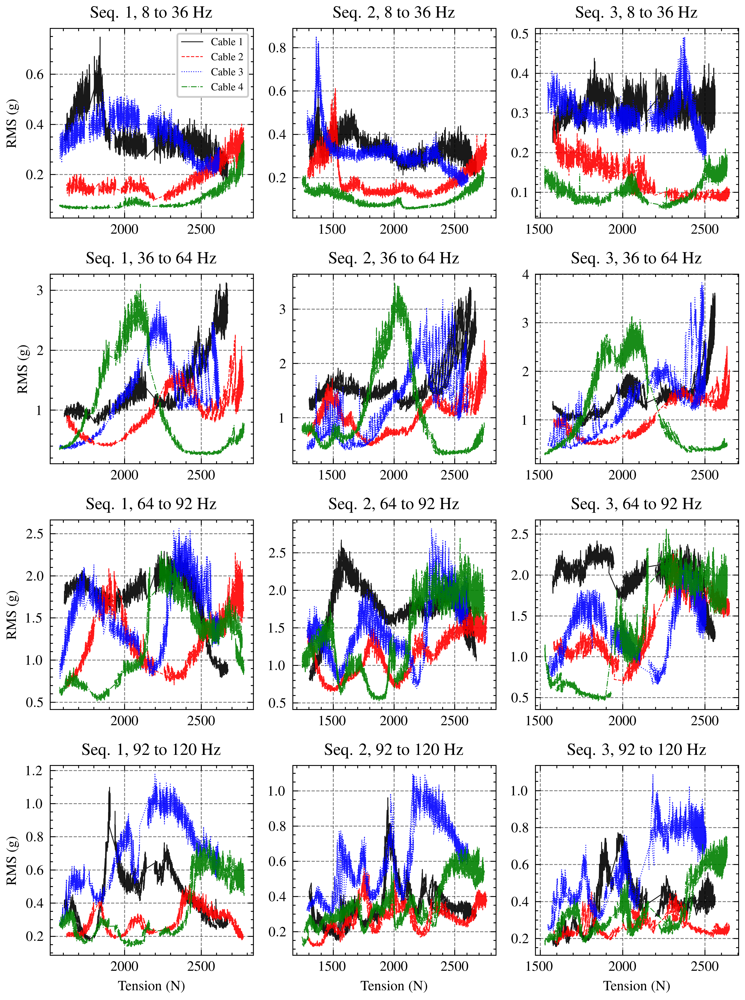

In [63]:
fig, axs = plt.subplots(4, 3, figsize=(6, 8), sharex=False, sharey=False)

for i in range(len(f_ranges)):
    # plt.subplot(4,3,i+1)
    for j in [1,2,3]:
        tension_per_seq = [tension_per_cable_s1, tension_per_cable_s2, tension_per_cable_s3]
        for cable in CABLES:
            #plt.subplot(4,3,3*i+1)
            axs[i,j-1].plot(tension_per_seq[j-1][cable], rms_per_seq[(j, cable, "radial")][:,i], alpha=0.9, linewidth=0.5)
        if i == len(f_ranges)-1:
            axs[i,j-1].set_xlabel("Tension (N)")
        if j == 1:
            axs[i,j-1].set_ylabel("RMS (g)")
        axs[i,j-1].set_title(f"Seq. {j}, {f_ranges[i][0]} to {f_ranges[i][1]} Hz")
        if i == 0 and j == 1:
            axs[i,j-1].legend([f"Cable {c}" for c in CABLES], fontsize=6)
plt.tight_layout()

fig.savefig(
    f"figures_frf_eda/psd_rms_1.png", dpi=300
)

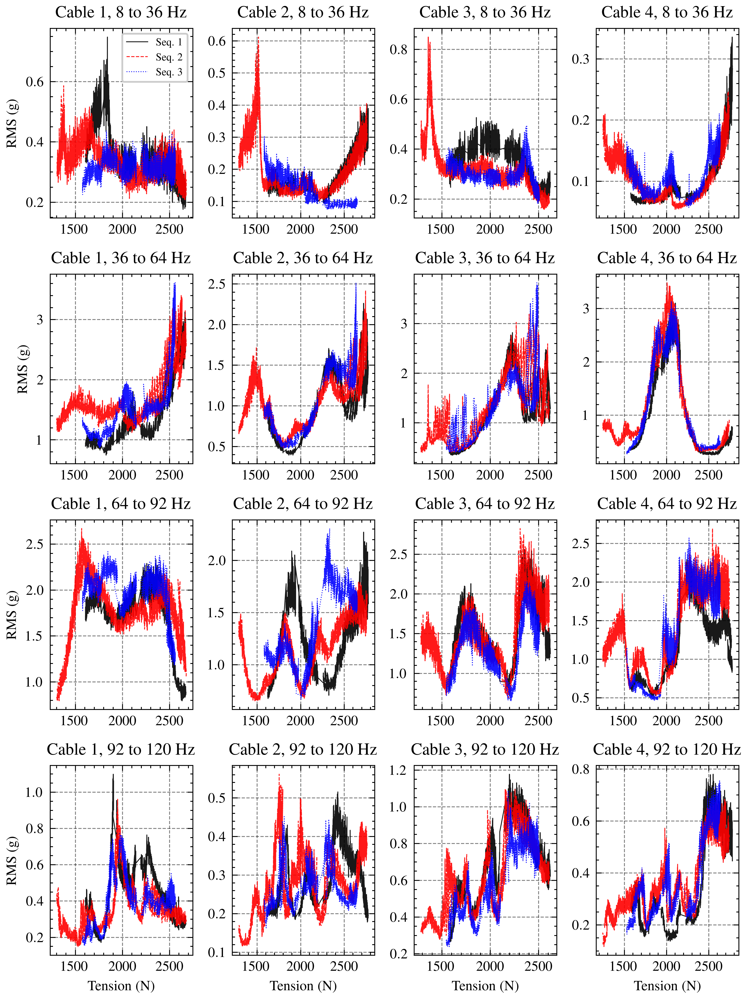

In [67]:
fig, axs = plt.subplots(4, 4, figsize=(6, 8), sharex=False, sharey=False)
tension_per_seq = [tension_per_cable_s1, tension_per_cable_s2, tension_per_cable_s3]

for i in range(len(f_ranges)):
    for cable in CABLES:
        for j in [1,2,3]:     
            axs[i,cable-1].plot(tension_per_seq[j-1][cable], rms_per_seq[(j, cable, "radial")][:,i], alpha=0.9, linewidth=0.5)
        if i == len(f_ranges)-1:
            axs[i,cable-1].set_xlabel("Tension (N)")
        if cable == 1:
            axs[i,cable-1].set_ylabel("RMS (g)")
        axs[i,cable-1].set_title(f"Cable {cable}, {f_ranges[i][0]} to {f_ranges[i][1]} Hz")
        if i == 0 and cable == 1:
            axs[i,cable-1].legend([f"Seq. {k}" for k in [1,2,3]], fontsize=6)

plt.tight_layout()
fig.savefig(
    f"figures_frf_eda/psd_rms_2.png", dpi=300
)

In [ ]:
fig, axs = plt.subplots(4, 4, figsize=(6, 8), sharex=True, sharey=False)
tension_per_seq = [tension_per_cable_s1, tension_per_cable_s2, tension_per_cable_s3]

for i in range(len(f_ranges)):
    # plt.subplot(4,3,i+1)
    for cable in CABLES:
        for j in [1,2,3]:        
            #plt.subplot(4,3,3*i+1)
            axs[i,j-1].plot(tension_per_seq[j-1][cable], rms_per_seq[(j, cable, "radial")][:,i], alpha=0.9, linewidth=0.5)

plt.tight_layout()

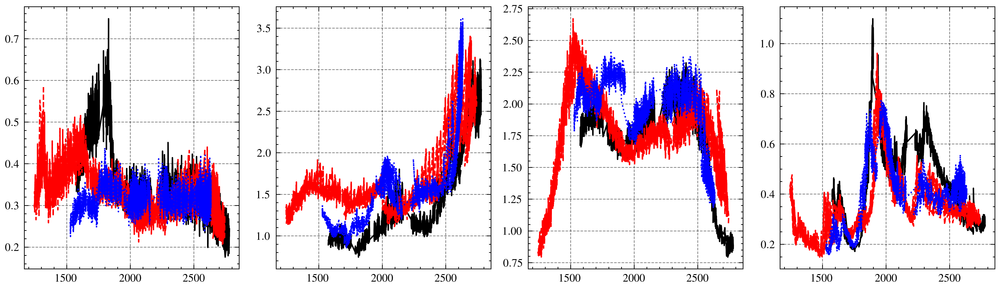

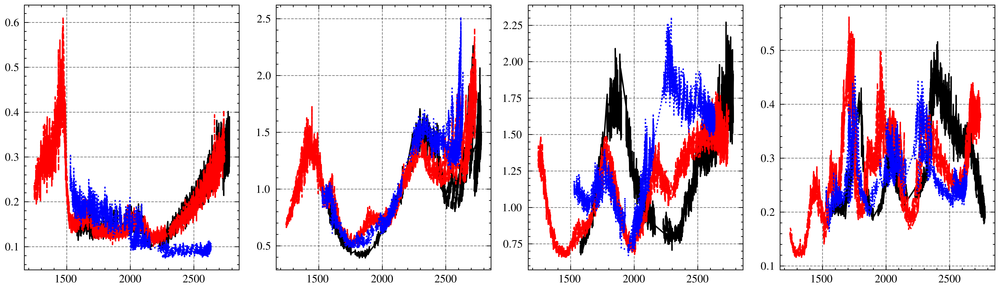

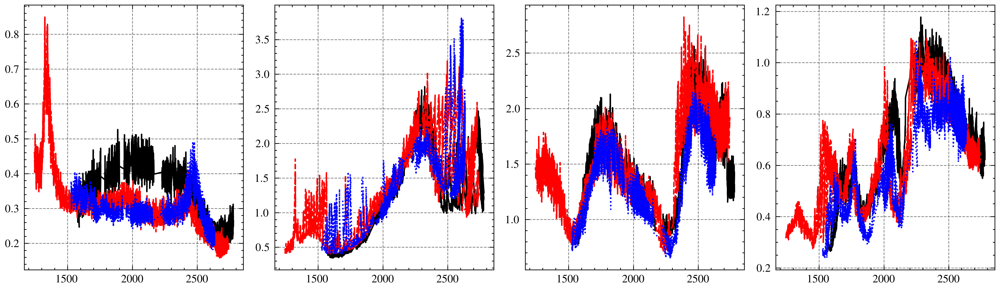

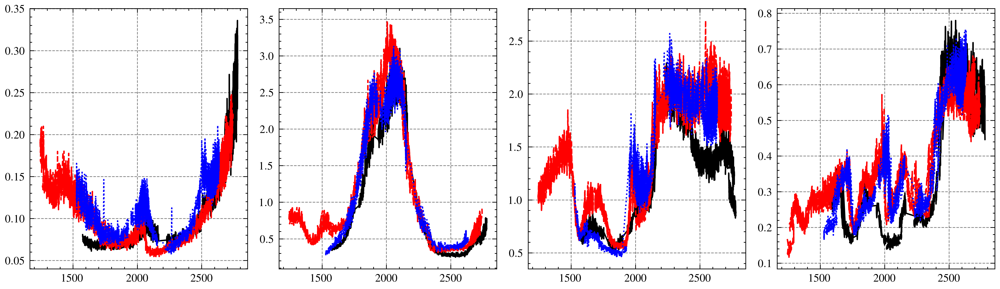

In [38]:
plt.figure(figsize=(10, 3))
for i in range(len(f_ranges)):
    plt.subplot(1,4,i+1)
    plt.plot(tension_per_cable_s1[cable], rms_1[(1, "radial")][:,i])
    plt.plot(tension_per_cable_s2[cable], rms_2[(1, "radial")][:,i])
    plt.plot(tension_per_cable_s3[cable], rms_3[(1, "radial")][:,i])
plt.tight_layout()

plt.figure(figsize=(10, 3))
for i in range(len(f_ranges)):
    plt.subplot(1,4,i+1)
    plt.plot(tension_per_cable_s1[cable], rms_1[(2, "radial")][:,i])
    plt.plot(tension_per_cable_s2[cable], rms_2[(2, "radial")][:,i])
    plt.plot(tension_per_cable_s3[cable], rms_3[(2, "radial")][:,i])
plt.tight_layout()

plt.figure(figsize=(10, 3))
for i in range(len(f_ranges)):
    plt.subplot(1,4,i+1)
    plt.plot(tension_per_cable_s1[cable], rms_1[(3, "radial")][:,i])
    plt.plot(tension_per_cable_s2[cable], rms_2[(3, "radial")][:,i])
    plt.plot(tension_per_cable_s3[cable], rms_3[(3, "radial")][:,i])
plt.tight_layout()

plt.figure(figsize=(10, 3))
for i in range(len(f_ranges)):
    plt.subplot(1,4,i+1)
    plt.plot(tension_per_cable_s1[cable], rms_1[(4, "radial")][:,i])
    plt.plot(tension_per_cable_s2[cable], rms_2[(4, "radial")][:,i])
    plt.plot(tension_per_cable_s3[cable], rms_3[(4, "radial")][:,i])
plt.tight_layout()